## Figure 3: Reported Crash, Fire, and Injury Rates Across Vehicle Components

This analysis compares the percentage of complaints involving crashes, fires, and injuries across different vehicle component categories.

By looking beyond total complaint counts, we aim to explore whether certain components are associated with more serious reported incidents and whether these patterns could provide useful features for predicting future NHTSA safety investigations.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROJECT_ROOT = Path.cwd().parents[1]
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "complaints_clean.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (9461, 15)


,complaint_id,make,model,model_year,product_model,filed_date,incident_date,components,crash,fire,number_of_injuries,number_of_deaths,summary,reporting_delay,invalid_incident_date
0,11770133,TOYOTA,CAMRY,2018,CAMRY,2026-10-09,2026-09-29,POWER TRAIN,False,False,0,0,"Total transmission failure at about 107,770 mi...",10.0,False
1,11769969,TOYOTA,CAMRY,2018,CAMRY,2026-10-08,2026-10-06,ENGINE,False,False,0,0,My 2018 Toyota Camry LE went into Limp mode wh...,2.0,False
2,11769124,TOYOTA,CAMRY,2018,CAMRY,2026-10-05,2026-10-03,POWER TRAIN,False,False,0,0,The contact owns a 2018 Toyota Camry. The cont...,2.0,False
3,11768868,TOYOTA,CAMRY,2018,CAMRY,2026-10-04,2026-10-02,FUEL/PROPULSION SYSTEM,False,False,0,0,I am filing a formal complaint regarding a sev...,2.0,False
4,11768335,TOYOTA,CAMRY,2018,CAMRY,2026-10-01,2026-09-29,POWER TRAIN,False,False,0,0,"2018 Toyota Camry approx 126,000 miles. Trans...",2.0,False


In [4]:
# Figure 3: Severity Data Quality Check

print("Data types:")
print(df[["crash", "fire", "number_of_injuries"]].dtypes)

print("\nMissing values:")
print(df[["crash", "fire", "number_of_injuries"]].isna().sum())

print("\nCrash distribution:")
display(df["crash"].value_counts(dropna=False))

print("\nFire distribution:")
display(df["fire"].value_counts(dropna=False))

print("\nInjury distribution:")
display(df["number_of_injuries"].value_counts(dropna=False).sort_index())

print("\nSummary statistics:")
display(df["number_of_injuries"].describe())

Data types:
crash                  bool
fire                   bool
number_of_injuries    int64
dtype: object

Missing values:
crash                 0
fire                  0
number_of_injuries    0
dtype: int64

Crash distribution:


crash
False    9092
True      369
Name: count, dtype: int64


Fire distribution:


fire
False    9392
True       69
Name: count, dtype: int64


Injury distribution:


number_of_injuries
0     9218
1      182
2       49
3        4
4        5
5        1
6        1
10       1
Name: count, dtype: int64


Summary statistics:


count    9461.000000
mean        0.035197
std         0.260768
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        10.000000
Name: number_of_injuries, dtype: float64

In [6]:
import re

component_categories = [
    "ENGINE",
    "POWER TRAIN",
    "ELECTRICAL SYSTEM",
    "SERVICE BRAKES",
    "STEERING",
    "STRUCTURE",
    "AIR BAGS",
    "FUEL/PROPULSION SYSTEM",
    "VEHICLE SPEED CONTROL",
    "FORWARD COLLISION AVOIDANCE"
]

severity_df = df.copy()

severity_df["injury_reported"] = (
    severity_df["number_of_injuries"] > 0
)

results = []

for component in component_categories:

    pattern = (
        r"(?<![A-Z0-9])"
        + re.escape(component)
        + r"(?![A-Z0-9])"
    )

    mask = severity_df["components"].fillna("").str.contains(
        pattern,
        regex=True
    )

    subset = severity_df.loc[mask]

    results.append({
        "Component": component,
        "Complaints": len(subset),
        "Crash (%)": subset["crash"].mean() * 100,
        "Fire (%)": subset["fire"].mean() * 100,
        "Injury (%)": subset["injury_reported"].mean() * 100
    })

severity_summary = pd.DataFrame(results)

display(severity_summary.round(2))

,Component,Complaints,Crash (%),Fire (%),Injury (%)
0,ENGINE,3184,1.01,0.97,0.53
1,POWER TRAIN,1440,1.67,0.14,1.04
2,ELECTRICAL SYSTEM,1098,3.64,2.00,2.37
3,SERVICE BRAKES,596,15.10,0.67,5.20
4,STEERING,623,6.26,0.64,2.41
5,STRUCTURE,871,2.76,0.23,3.10
6,AIR BAGS,320,36.56,0.62,28.75
7,FUEL/PROPULSION SYSTEM,614,1.63,0.81,0.65
8,VEHICLE SPEED CONTROL,301,10.63,0.33,4.98
9,FORWARD COLLISION AVOIDANCE,419,10.26,0.48,5.73


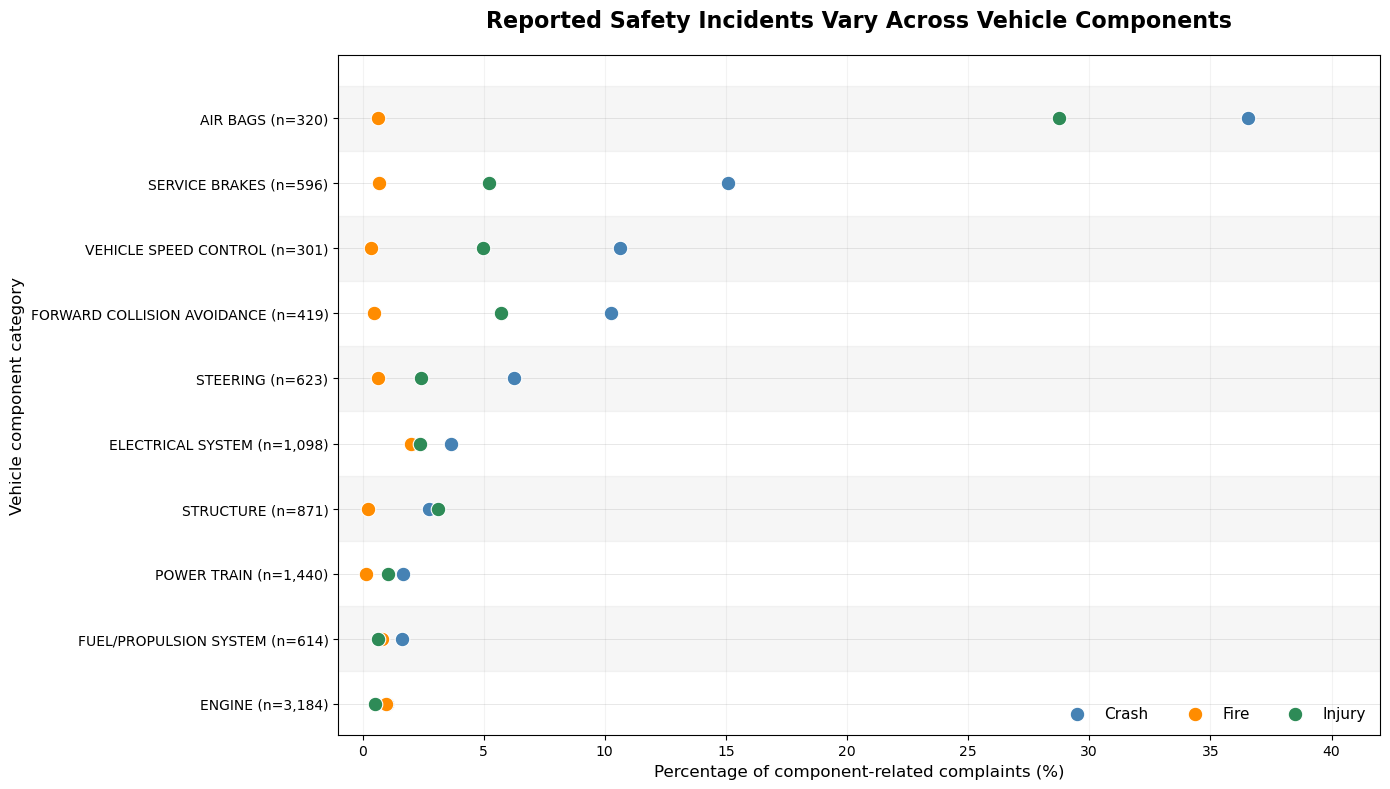

In [18]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MultipleLocator

# Prepare component-level severity statistics
plot_df = severity_summary.copy()
plot_df = plot_df.sort_values(
    "Crash (%)", ascending=False
).reset_index(drop=True)

y = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(14, 8))

# Add alternating row backgrounds and horizontal guides
for i in range(len(plot_df)):
    if i % 2 == 0:
        ax.axhspan(i - 0.5, i + 0.5, color="gray", alpha=0.07)

    ax.axhline(i, color="gray", linewidth=0.5, alpha=0.25)

# Plot all incident types on the same component row
metrics = {
    "Crash (%)": ("Crash", "steelblue"),
    "Fire (%)": ("Fire", "darkorange"),
    "Injury (%)": ("Injury", "seagreen")
}

for column, (label, color) in metrics.items():
    ax.scatter(
        plot_df[column],
        y,
        s=110,
        color=color,
        label=label,
        edgecolor="white",
        linewidth=0.8,
        zorder=3
    )

# Display component labels and complaint sample sizes
labels = [
    f"{row['Component']} (n={row['Complaints']:,})"
    for _, row in plot_df.iterrows()
]

ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=10)
ax.invert_yaxis()

# Configure axes
ax.set_xlim(-1, 42)
ax.xaxis.set_major_locator(MultipleLocator(5))

ax.set_xlabel("Percentage of component-related complaints (%)", fontsize=12)
ax.set_ylabel("Vehicle component category", fontsize=12)

ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

# Add title and legend
ax.set_title(
    "Reported Safety Incidents Vary Across Vehicle Components",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.legend(
    loc="lower right",
    ncol=3,
    frameon=False,
    fontsize=11
)

plt.tight_layout()

# Save the final figure
fig.savefig(
    PROJECT_ROOT / "figures" / "component_severity_dotplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Key Findings

- **Air Bags** have the highest reported crash (36.6%) and injury (28.7%) percentages among the selected components.
- **Electrical System** has the highest reported fire percentage (2.0%).
- **Engine** has the largest number of complaints (3,184), but relatively low crash (1.0%) and injury (0.5%) percentages.
- These findings suggest that complaint volume alone may not capture reported safety severity. Including crash, fire, and injury information could provide useful features for predicting future NHTSA investigations.